# 14 · Dense FIMI datasets: out-of-sample test of the cost model  (VM; lite ≈ 30–60 min)

**Why.** All 18 paper datasets are sparse (density d_avg/N ≤ 2.6 %) and have P1 ≥ 23 at s = 1e-4;
scatter beat classic on every one of the 17 correlation points (1.6–413×). The 0.95 correlation
therefore shows that the *size* of the speedup follows P1, but never tests the *crossover*. On the
dense half of the FIMI repository (chess 49 %, connect 33 %, mushroom 19 %, accidents 7 %, pumsb
3.5 % density) P1 is about 0.5–8, i.e. d_avg(1+d_CV²) approaches |F1|, where the model predicts that
candidate intersection (`classic`, Eclat's level 2) matches or beats scatter. This notebook tests that
prediction on data the model was not developed on. Either outcome is reportable.

**Lite design (default).**

| part | datasets | supports | k | methods |
|---|---|---|---|---|
| A · cost model only | all five | 0.5 … 1e-3 | – | P1, F1, density (no mining) |
| B · pairwise crossover | all five | 0.5, 0.1, 0.05, 0.01, 0.005, 1e-3 | 2 | `hyb_1t`, `classic_1t`, `hyb`, `classic`, `borgelt_apriori`, `borgelt_eclat` |
| C · higher order (optional) | chess, mushroom, connect | same | 3 | `hyb`, `hyb_1t`, `borgelt_eclat`, `borgelt_fpgrowth`, `lcm` |

Supports stop at **1e-3** (author decision, 29 Oct: 1e-4 is not feasible on dense data). The grid
runs from high to low support and, per method, stops descending after its first timeout/OOM
(recorded, not hidden). Classic and scatter are compared at **matched threads** (1/1 and 8/8), so the
thread question of the 0.95 does not arise here.

`SMOKE = True` runs chess at two supports, one measured run, into a separate experiment
(`fimi_lite_smoke`) to check the setup in a minute. `RUN_FULL = True` runs the full grid
(nine k = 2 methods, k = 3–4, supports to 1e-4); it is open-ended and OOM-prone.

Output: `results/runs/<campaign>/fimi_lite.csv` (smoke: `fimi_lite_smoke.csv`; full: `fimi_dense.csv`),
plus `fimi_lite_crossover.csv` / `.png`.

In [1]:
import os, sys, json, math, time
from pathlib import Path
BUNDLE = Path.cwd().resolve().parent     # notebooks run from <bundle>/notebooks
assert (BUNDLE / "bench" / "exp_runners.py").exists(), "start Jupyter in <bundle>/notebooks"
sys.path.insert(0, str(BUNDLE / "bench"))
# Results of these notebooks go to results/runs/<FA_CAMPAIGN>/ (set it before starting Jupyter
# to keep campaigns apart; every run_grid call also appends to manifest.jsonl there).
os.environ.setdefault("FA_CAMPAIGN", "new_campaign")
import numpy as np, pandas as pd
import exp_runners as pr
import exp_data as pdd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("campaign", pr.CAMPAIGN, "->", pr.RESULTS)
print("build", pr.build_id(), "| extension", pr.ext_path())

campaign vm_20261029 -> /home/user/artifacts/results/runs/vm_20261029
build cc508b6408f4 | extension /home/user/.venvs/fastapriori/lib/python3.12/site-packages/fastapriori/_fastapriori_rs.cpython-312-x86_64-linux-gnu.so


In [2]:
SMOKE = False          # True: chess, two supports, one measured run, experiment "fimi_lite_smoke"
RUN_K3 = True          # part C
RUN_FULL = False       # the full open-ended grid (supports to 1e-4, k = 3-4, nine methods)

FIMI = ["chess", "mushroom", "connect", "accidents", "pumsb"]          # small -> large
SUPPORTS = [0.5, 0.1, 0.05, 0.01, 0.005, 1e-3]                          # high -> low
K2_METHODS = ["hyb_1t", "classic_1t", "hyb", "classic", "borgelt_apriori", "borgelt_eclat"]
K3_DATASETS = ["chess", "mushroom", "connect"]
K3_METHODS = ["hyb", "hyb_1t", "borgelt_eclat", "borgelt_fpgrowth", "lcm"]
REPEATS, WARMUP, TIMEOUT_S = 3, 1, 600
EXPERIMENT = "fimi_lite"
if SMOKE:
    FIMI, K3_DATASETS, SUPPORTS = ["chess"], ["chess"], [0.5, 0.1]
    REPEATS, WARMUP, TIMEOUT_S, EXPERIMENT = 1, 0, 120, "fimi_lite_smoke"
pr.RESULTS.mkdir(parents=True, exist_ok=True)
print(f"{EXPERIMENT}: {FIMI} x {SUPPORTS}, repeats={REPEATS}, warm-up={WARMUP}, timeout={TIMEOUT_S}s")

def descend(dataset, methods, ks, experiment=EXPERIMENT, supports=SUPPORTS, timeout_s=TIMEOUT_S,
            repeats=REPEATS, warmup=WARMUP):
    """Run supports high -> low; a method that fails (timeout/oom) at support s for the smallest k
    is not run at lower supports (more work), and the failure stays in the CSV."""
    alive = list(methods)
    for s in supports:
        if not alive:
            break
        res = pr.run_grid(experiment, [dataset], alive, ks=ks, supports=[s], timeout_s=timeout_s,
                          repeats=repeats, warmup=warmup)
        cell = res[(res.dataset == dataset) & np.isclose(res.min_support, s) & (res.k == min(ks))]
        dead = set(cell[cell.status.isin(["timeout", "oom"])].method)
        if dead:
            print(f"{dataset} s={s:g}: stop descending for {sorted(dead)}")
        alive = [m for m in alive if m not in dead]

fimi_lite: ['chess', 'mushroom', 'connect', 'accidents', 'pumsb'] x [0.5, 0.1, 0.05, 0.01, 0.005, 0.001], repeats=3, warm-up=1, timeout=600s


## A · Cost-model statistics (no mining)

P1 = (|F1| − 1) / (d_avg (1 + d_CV²)) per dataset and support, as in the paper (raw widths). The
17 correlation datasets have P1 between 23 and 2,811 at s = 1e-4.

In [3]:
rows = []
for n in FIMI:
    df = pdd.fetch_fimi(n)
    for st in pdd.cost_stats(df, SUPPORTS):
        rows.append(dict(dataset=n, min_support=st["min_support"], D=st["D"], N=st["N"], d_avg=st["d_avg"],
                         density=st["d_avg"] / st["N"], d_cv=st["d_cv"], F1=st["F1"], P1=st["P1_raw"]))
cost = pd.DataFrame(rows)
cost.to_csv(pr.RESULTS / f"{EXPERIMENT}_cost_stats.csv", index=False)
display(cost.round(3))

,dataset,min_support,D,N,d_avg,density,d_cv,F1,P1
0,chess,0.500,3196,75,37.000,0.493,0.000,37,0.973
1,chess,0.100,3196,75,37.000,0.493,0.000,61,1.622
2,chess,0.050,3196,75,37.000,0.493,0.000,66,1.757
3,chess,0.010,3196,75,37.000,0.493,0.000,71,1.892
4,chess,0.005,3196,75,37.000,0.493,0.000,72,1.919
5,chess,0.001,3196,75,37.000,0.493,0.000,74,1.973
6,mushroom,0.500,8416,119,23.000,0.193,0.000,13,0.522
7,mushroom,0.100,8416,119,23.000,0.193,0.000,55,2.348
8,mushroom,0.050,8416,119,23.000,0.193,0.000,74,3.174
9,mushroom,0.010,8416,119,23.000,0.193,0.000,96,4.130


## B · Pairwise crossover (k = 2)

In [4]:
pr.preflight(K2_METHODS)
for n in FIMI:
    descend(n, K2_METHODS, ks=[2])

preflight ok: 6 methods, build cc508b6408f4
preflight ok: 6 methods, build cc508b6408f4


fimi_lite:   0%|          | 0/6 [00:00<?, ?cell/s]

[fimi_lite] chess | hyb_1t | k=2 s=0.5 run 0: ok wall=0.013900830999773461 rss=125644.0 (0.5s)


[fimi_lite] chess | hyb_1t | k=2 s=0.5 run 1: ok wall=0.013369249001698336 rss=125548.0 (0.5s)


[fimi_lite] chess | hyb_1t | k=2 s=0.5 run 2: ok wall=0.013275014000100782 rss=125704.0 (0.4s)


[fimi_lite] chess | hyb_1t | k=2 s=0.5 run 3: ok wall=0.01359030499952496 rss=126040.0 (0.4s)


... (651 outputs left out)

[fimi_lite] pumsb | borgelt_eclat | k=2 s=0.001 run 0: ok wall=2.99 rss=68184.0 (3.0s)


[fimi_lite] pumsb | borgelt_eclat | k=2 s=0.001 run 1: ok wall=2.95 rss=68408.0 (3.0s)


[fimi_lite] pumsb | borgelt_eclat | k=2 s=0.001 run 2: ok wall=2.99 rss=68464.0 (3.0s)


[fimi_lite] pumsb | borgelt_eclat | k=2 s=0.001 run 3: ok wall=2.98 rss=68348.0 (3.0s)


## C · Higher order (k = 3, optional)

HybridFIM is expected to be weakest here (dense lattices); the small datasets only.

In [5]:
if RUN_K3:
    pr.preflight(K3_METHODS)
    for n in K3_DATASETS:
        descend(n, K3_METHODS, ks=[3])

preflight ok: 5 methods, build cc508b6408f4
preflight ok: 5 methods, build cc508b6408f4


fimi_lite:   0%|          | 0/5 [00:00<?, ?cell/s]

[fimi_lite] chess | hyb | k=3 s=0.5 run 0: ok wall=0.06483588199989754 rss=179544.0 (0.5s)


[fimi_lite] chess | hyb | k=3 s=0.5 run 1: ok wall=0.06368163400111371 rss=176748.0 (0.5s)


[fimi_lite] chess | hyb | k=3 s=0.5 run 2: ok wall=0.06451860699962708 rss=179852.0 (0.5s)


[fimi_lite] chess | hyb | k=3 s=0.5 run 3: ok wall=0.06409063399769366 rss=179532.0 (0.5s)


... (278 outputs left out)

[fimi_lite] connect | lcm | k=3 s=0.001 run 0: ok wall=5.07 rss=30876.0 (5.1s)


[fimi_lite] connect | lcm | k=3 s=0.001 run 1: ok wall=5.1 rss=30876.0 (5.1s)


[fimi_lite] connect | lcm | k=3 s=0.001 run 2: ok wall=5.07 rss=30816.0 (5.1s)


[fimi_lite] connect | lcm | k=3 s=0.001 run 3: ok wall=5.04 rss=30812.0 (5.1s)


## Results

Median wall time per cell, failures, count agreement, and the crossover test: classic ÷ scatter at
matched threads against P1. A ratio below 1 means candidate intersection won. Chess and mushroom are
small (3k and 8k transactions): many of their runs take milliseconds, where fixed per-call costs
dominate, so a ratio counts toward the test only if both runs take at least `MIN_RESOLVED_S`
(unresolved cells are shown hollow and listed, not dropped silently).

In [6]:
raw = pr.load_results(EXPERIMENT)
summ = pr.summarize(raw)
fails = raw[raw.status != "ok"].groupby(["dataset", "k", "min_support", "method", "status"]).size()
print("failed / skipped cells:", "none" if fails.empty else ""); display(fails.to_frame("runs")) if not fails.empty else None
bad = pr.check_agreement(summ)
print("count disagreements:", len(bad)); display(bad) if len(bad) else None
for k in sorted(summ.k.unique()):
    w = summ[summ.k == k].pivot_table(index=["dataset", "min_support"], columns="method", values="wall_s")
    print(f"k = {k}: median wall s"); display(w.round(3))

failed / skipped cells: none
count disagreements: 0
k = 2: median wall s


method                 borgelt_apriori  borgelt_eclat  classic  classic_1t    hyb  hyb_1t
dataset   min_support                                                                    
accidents 0.001                   1.01           5.46    2.893       8.765  0.723   1.233
          0.005                   1.01           5.03    2.680       7.993  0.717   1.229
          0.010                   1.01           4.86    2.595       7.599  0.709   1.251
          0.050                   1.00           3.92    2.286       6.010  0.710   1.287
          0.100                   1.00           3.50    2.125       4.884  0.719   1.295
          0.500                   0.66           0.72    2.207       2.192  0.722   1.285
chess     0.001                   0.01           0.03    0.023       0.036  0.011   0.014
          0.005                   0.01           0.03    0.024       0.036  0.011   0.014
          0.010                   0.01           0.03    0.023       0.037  0.011   0.014
          0.050                   0.01           0.03    0.023       0.036  0.011   0.014
          0.100                   0.01           0.03    0.022       0.035  0.011   0.014
          0.500                   0.01           0.01    0.021       0.025  0.010   0.013
connect   0.001                   0.20           0.83    0.509       1.105  0.174   0.311
          0.005                   0.20           0.83    0.501       1.071  0.177   0.306
          0.010                   0.20           0.82    0.494       1.051  0.171   0.294
          0.050                   0.20           0.76    0.472       0.943  0.174   0.288
          0.100                   0.22           0.65    0.453       0.848  0.173   0.303
          0.500                   0.14           0.15    0.405       0.530  0.171   0.312
mushroom  0.001                   0.01           0.03    0.036       0.052  0.014   0.018
          0.005                   0.01           0.03    0.035       0.050  0.014   0.017
          0.010                   0.01           0.03    0.034       0.048  0.014   0.018
          0.050                   0.01           0.02    0.033       0.043  0.014   0.017
          0.100                   0.01           0.02    0.032       0.039  0.014   0.017
          0.500                   0.00           0.00    0.029       0.030  0.014   0.017
pumsb     0.001                   0.36           2.98    1.978       7.543  0.264   0.592
          0.005                   0.35           2.79    1.306       5.042  0.256   0.580
          0.010                   0.35           2.67    1.126       4.217  0.250   0.582
          0.050                   0.34           2.08    0.799       2.617  0.246   0.576
          0.100                   0.33           1.66    0.733       2.209  0.253   0.564
          0.500                   0.21           0.28    0.499       0.784  0.250   0.581

k = 3: median wall s


method                borgelt_eclat  borgelt_fpgrowth    hyb  hyb_1t   lcm
dataset  min_support                                                      
chess    0.001                 0.21              0.15  0.354   0.572  0.36
         0.005                 0.20              0.15  0.339   0.548  0.35
         0.010                 0.20              0.15  0.313   0.528  0.35
         0.050                 0.18              0.13  0.239   0.428  0.30
         0.100                 0.15              0.11  0.200   0.374  0.24
         0.500                 0.02              0.02  0.064   0.142  0.02
connect  0.001                 2.56              0.82  2.345   7.677  5.07
         0.005                 2.52              0.78  2.132   7.175  4.77
         0.010                 2.41              0.73  2.029   7.449  4.32
         0.050                 1.61              0.46  1.618   6.857  2.30
         0.100                 1.01              0.32  1.405   6.714  1.26
         0.500                 0.16              0.15  0.778   3.405  0.18
mushroom 0.001                 0.06              0.03  0.260   0.405  0.07
         0.005                 0.06              0.03  0.217   0.365  0.07
         0.010                 0.05              0.02  0.189   0.305  0.06
         0.050                 0.03              0.01  0.101   0.201  0.03
         0.100                 0.02              0.01  0.067   0.145  0.02
         0.500                 0.00              0.00  0.033   0.033  0.00

In [7]:
MIN_RESOLVED_S = 0.1   # a ratio counts only if both runs take at least this long (else fixed costs dominate)
w2 = summ[summ.k == 2].pivot_table(index=["dataset", "min_support"], columns="method", values="wall_s")
x = cost.set_index(["dataset", "min_support"])[["density", "F1", "P1"]].join(w2, how="inner")
PAIRS = {"classic/scatter 1T": ("classic_1t", "hyb_1t"), "classic/scatter 8T": ("classic", "hyb")}
for col, (num, den) in PAIRS.items():
    if {num, den} <= set(x.columns):
        x[col] = x[num] / x[den]
        x[col + " resolved"] = np.minimum(x[num], x[den]) >= MIN_RESOLVED_S
ext = [c for c in ("borgelt_apriori", "borgelt_eclat") if c in x.columns]
if ext and "hyb_1t" in x.columns:
    x["best Borgelt / scatter 1T"] = x[ext].min(axis=1) / x["hyb_1t"]
ratio_cols = [c for c in x.columns if "/" in c and not c.endswith("resolved")]
x.to_csv(pr.RESULTS / f"{EXPERIMENT}_crossover.csv")
display(x[["density", "F1", "P1"] + ratio_cols + [c for c in x.columns if c.endswith("resolved")]].round(3))

from scipy import stats
for c in PAIRS:
    if c not in x.columns:
        continue
    v = x.loc[x[c + " resolved"], ["P1", c]].dropna()
    print(f"{c}: {len(v)} of {x[c].notna().sum()} cells resolved (both >= {MIN_RESOLVED_S}s)")
    if len(v) >= 3:
        rho = stats.spearmanr(v.P1, v[c])[0]
        print(f"   Spearman(P1, ratio) = {rho:.3f}; cells where scatter loses (ratio < 1): {int((v[c] < 1).sum())}; "
              f"lowest-P1 resolved cell: P1 = {v.sort_values('P1').P1.iloc[0]:.2f}, ratio = {v.sort_values('P1')[c].iloc[0]:.3f}")

density    F1      P1  classic/scatter 1T  classic/scatter 8T  best Borgelt / scatter 1T  classic/scatter 1T resolved  classic/scatter 8T resolved
dataset   min_support                                                                                                                                                    
chess     0.500          0.493    37   0.973               1.875               2.012                      0.748                        False                        False
          0.100          0.493    61   1.622               2.439               2.120                      0.706                        False                        False
          0.050          0.493    66   1.757               2.589               2.157                      0.721                        False                        False
          0.010          0.493    71   1.892               2.699               2.146                      0.736                        False                        False
          0.005          0.493    72   1.919               2.646               2.217                      0.727                        False                        False
          0.001          0.493    74   1.973               2.528               2.139                      0.693                        False                        False
mushroom  0.500          0.193    13   0.522               1.766               2.144                      0.000                        False                        False
          0.100          0.193    55   2.348               2.257               2.361                      0.584                        False                        False
          0.050          0.193    74   3.174               2.491               2.399                      0.580                        False                        False
          0.010          0.193    96   4.130               2.719               2.435                      0.571                        False                        False
          0.005          0.193   109   4.696               2.840               2.436                      0.574                        False                        False
          0.001          0.193   115   4.957               2.907               2.540                      0.563                        False                        False
connect   0.500          0.333    38   0.860               1.698               2.362                      0.448                         True                         True
          0.100          0.333    73   1.674               2.798               2.612                      0.726                         True                         True
          0.050          0.333    86   1.977               3.272               2.717                      0.694                         True                         True
          0.010          0.333   109   2.512               3.580               2.886                      0.681                         True                         True
          0.005          0.333   115   2.651               3.505               2.834                      0.654                         True                         True
          0.001          0.333   125   2.884               3.556               2.929                      0.644                         True                         True
accidents 0.500          0.072    24   0.675               1.706               3.056                      0.514                         True                         True
          0.100          0.072    75   2.172               3.770               2.956                      0.772                         True                         True
          0.050          0.072   105   3.053               4.671               3.222                      0.777                         True                         True
          0.010          0.072   166   4.844               6.077               3.661                      0.808  

classic/scatter 1T: 18 of 30 cells resolved (both >= 0.1s)
   Spearman(P1, ratio) = 0.909; cells where scatter loses (ratio < 1): 0; lowest-P1 resolved cell: P1 = 0.68, ratio = 1.706
classic/scatter 8T: 18 of 30 cells resolved (both >= 0.1s)
   Spearman(P1, ratio) = 0.829; cells where scatter loses (ratio < 1): 0; lowest-P1 resolved cell: P1 = 0.68, ratio = 3.056


The figure puts the FIMI cells next to the 17 May correlation datasets (classic-8T ÷ scatter-8T,
k = 2, s = 1e-4, the matched-thread version of the published 0.95) on the same axes.

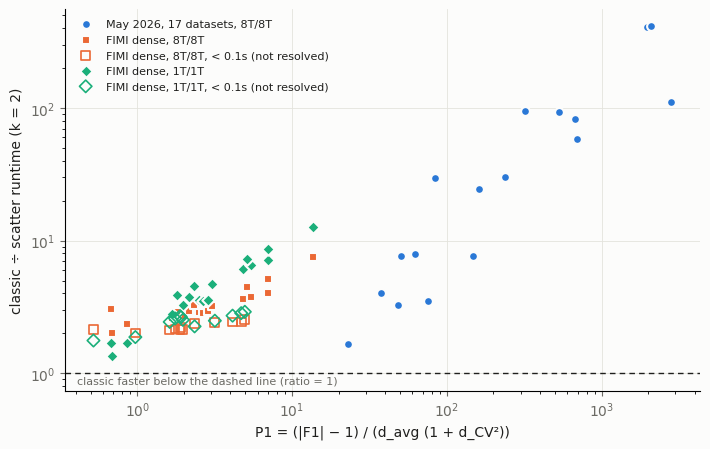

In [8]:
import matplotlib.pyplot as plt
INK, MUTED, GRID, SURFACE = "#1f1f1d", "#6b6a64", "#e4e3dd", "#fcfcfb"
C_MAY, C_8T, C_1T = "#2a78d6", "#eb6834", "#1baf7a"     # categorical slots 1-3 (validated)

may = pd.read_csv(BUNDLE / "results" / "campaign_2026-05" / "results_rigorous_20260523_115442.csv")
may = may[(may.k == 2) & np.isclose(may.min_support, 1e-4) & (may.wall_s_n_ok == may.wall_s_n_runs)]
mw = may.pivot_table(index="dataset", columns="method", values="wall_s_median")[["fastapriori_classic", "fastapriori_fast"]].dropna()
cpath = BUNDLE / "results" / "derived" / "cost_stats.csv"
mc = pd.read_csv(cpath if cpath.exists() else BUNDLE / "results" / "campaign_2026-05" / "cost_stats_20261022.csv")
mc = mc[np.isclose(mc.min_support, 1e-4)].set_index("dataset")
mj = mc[["P1_raw"]].join((mw.fastapriori_classic / mw.fastapriori_fast).rename("ratio"), how="inner")

fig, ax = plt.subplots(figsize=(7.2, 4.6), facecolor=SURFACE); ax.set_facecolor(SURFACE)
ax.scatter(mj.P1_raw, mj.ratio, s=40, c=C_MAY, edgecolors=SURFACE, linewidths=1.5, label=f"May 2026, 17 datasets, 8T/8T", zorder=3)
for col, color, marker, lab in (("classic/scatter 8T", C_8T, "s", "FIMI dense, 8T/8T"),
                                ("classic/scatter 1T", C_1T, "D", "FIMI dense, 1T/1T")):
    if col in x.columns:
        v = x[["P1", col, col + " resolved"]].dropna()
        r = v[v[col + " resolved"].astype(bool)]
        u = v[~v[col + " resolved"].astype(bool)]
        ax.scatter(r.P1, r[col], s=40, c=color, marker=marker, edgecolors=SURFACE, linewidths=1.5, label=lab, zorder=3)
        ax.scatter(u.P1, u[col], s=40, marker=marker, facecolors="none", edgecolors=color, linewidths=1.2,
                   label=f"{lab}, < {MIN_RESOLVED_S}s (not resolved)" if len(u) else None, zorder=3)
ax.axhline(1.0, color=INK, linestyle=(0, (4, 3)), linewidth=1.0)
ax.set_xscale("log"); ax.set_yscale("log")
ax.text(0.02, 0.97, "classic faster below the dashed line (ratio = 1)", transform=ax.get_yaxis_transform(),
        va="top", color=MUTED, fontsize=8)
ax.set_xlabel("P1 = (|F1| − 1) / (d_avg (1 + d_CV²))", color=INK)
ax.set_ylabel("classic ÷ scatter runtime (k = 2)", color=INK)
ax.grid(color=GRID, linewidth=0.6); ax.set_axisbelow(True)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
ax.tick_params(colors=MUTED); ax.legend(frameon=False, fontsize=8, labelcolor=INK)
fig.tight_layout()
fig.savefig(pr.RESULTS / f"{EXPERIMENT}_crossover.png", dpi=200, facecolor=SURFACE)
plt.show()

## Full grid (optional, open-ended)

Nine k = 2 methods and eight k = 3–4 methods, supports 0.1 → 1e-4, experiment
`fimi_dense`. Low supports explode (pumsb: C(|F1|, 3) ≈ 8.7e8 candidates at 1e-4); keep
`FA_MEMOUT_GB` below the VM's RAM.

In [9]:
if RUN_FULL:
    FULL_SUPPORTS = [0.1, 0.05, 0.01, 0.005, 1e-3, 5e-4, 1e-4]
    FULL_K2 = ["hyb_1t", "hyb_sfx_1t", "hyb", "classic", "borgelt_apriori", "borgelt_eclat",
               "pyfim_apriori", "pyfim_eclat", "hyb_seeded_1t"]
    FULL_K34 = ["hyb", "hyb_seeded", "hyb_seeded_1t", "borgelt_eclat", "borgelt_fpgrowth",
                "pyfim_eclat", "pyfim_fpgrowth", "lcm"]
    for n in ["chess", "mushroom", "connect", "pumsb", "accidents"]:
        descend(n, FULL_K2, ks=[2], experiment="fimi_dense", supports=FULL_SUPPORTS, timeout_s=900, repeats=3, warmup=1)
    for n in ["chess", "mushroom", "connect", "pumsb", "accidents"]:
        descend(n, FULL_K34, ks=[3, 4], experiment="fimi_dense", supports=FULL_SUPPORTS, timeout_s=900, repeats=3, warmup=1)
    s = pr.summarize(pr.load_results("fimi_dense"))
    display(s[s.k == 2].pivot_table(index=["dataset", "min_support"], columns="method", values="wall_s").round(3))
    display(pr.check_agreement(s))